# Parameter inference tools

This notebook introduces the tools that the parameter inference algorithms in this repository are
built from: Markov chain Monte Carlo (MCMC), ensemble Kalman inversion (EKI), active subspaces and
the ways of estimating them, and reduced problems. Each tool is introduced on a small example
problem, first with a short mathematical description and then with the code that implements it.
The last sections put the tools together into a complete algorithm.

This notebook assumes you have worked through
[`main_inverse_problem.ipynb`](main_inverse_problem.ipynb), which introduces the inverse problem:
the prior, the forward model, the likelihood, the learning rate and the coordinate systems. The
mathematical details are collected in the last section, and the notation follows
[`docs/notation.md`](../docs/notation.md).

Running the whole notebook takes about two minutes.

In [1]:
import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from probpipe import sample, workflow_run

from lsmas import plots
from lsmas.algorithms import active_subspace_mcmc
from lsmas.data import load_harvard_forest
from lsmas.experiments import load_reference
from lsmas.problems import load_inverse_problem
from lsmas.tools import (
    LadderLinearization,
    Subspace,
    covariance_subspace,
    exact_subspace,
    jacobians,
    reduced_problem,
    statistical_linearization,
)

workflow_run.set_default(seed=0)  # every random call below continues one seeded stream

The cell below defines plotting helpers used in this notebook. It is collapsed; expand it to see the code.

In [2]:
def plot_misfit_against_variables(misfit, active, inactive):
    """The data misfit at each draw against its first active and its last inactive variable."""
    figure, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
    axes[0].plot(active, misfit, ".", ms=3, alpha=0.5)
    axes[0].set(xlabel="first active variable $a_1$", ylabel="misfit $\\Phi$")
    axes[1].plot(inactive, misfit, ".", ms=3, alpha=0.5, color="C1")
    axes[1].set(xlabel="last inactive variable $b_{d-r}$")
    axes[0].set_yscale("log")
    figure.tight_layout()


def plot_slope_against_jacobian(average_jacobian, slope):
    """Each entry of a statistical linearization against the same entry of the average Jacobian."""
    _, axis = plt.subplots(figsize=(4, 4))
    axis.plot(average_jacobian.ravel(), slope.ravel(), ".", ms=2, alpha=0.4)
    low = min(average_jacobian.min(), slope.min())
    high = max(average_jacobian.max(), slope.max())
    axis.plot([low, high], [low, high], "k", lw=0.6)
    axis.set(xlabel="average Jacobian entry", ylabel="statistical linearization entry")

## 1. Overview

Recall that our goal is to approximate the posterior

$$
\pi(\theta \mid y) \;\propto\; \pi_0(\theta) \prod_{i=1}^{n} p(y_i \mid \theta)^{\eta_i},
$$

with the learning rates $\eta_i$ from the previous notebook. For the Harvard Forest problem this is
hard for three reasons: every evaluation of the posterior density runs SIPNET, SIPNET does not
provide gradients, and there are 46 parameters.

The tools in this notebook come in two kinds:

1. **Posterior approximation.** MCMC draws samples whose distribution approaches the posterior. It
   is accurate given enough samples, but it needs many density evaluations, and its most efficient
   forms need gradients. EKI moves an ensemble of parameter values from the prior towards the
   posterior. It needs relatively few forward model runs and no gradients, but its result is only
   approximate.
2. **Parameter reduction.** The data typically inform only a few directions in parameter space
   (combinations of the parameters), while the prior alone determines the rest. The *active
   subspace* is spanned by the directions the data inform. If we can find it, we only need to
   sample those few directions.

The last section combines the two into one algorithm:

1. Run EKI to move from the prior to the region of the posterior.
2. Along the way, estimate the active subspace from the EKI ensembles, without gradients.
3. Run MCMC on the *reduced problem*: the posterior of the few active directions.
4. Map the samples back to all of the parameters.

## 2. A Toy Inverse Problem

Developing and checking algorithms directly on SIPNET is slow, and we have no exact answer to
compare against. The *toy problem* is a simplified version of SIPNET written in
[JAX](https://docs.jax.dev). It uses the same Harvard Forest data, likelihood and learning rates as
the `harvard_forest` problem, but it calibrates only 14 parameters, and its forward model is fast
and can be differentiated automatically. So for the toy problem we can compute exact gradients,
sample the posterior accurately with gradient-based MCMC, and check the gradient-free tools against
exact answers. The equations of the toy model are in the docstring of `lsmas.problems.toy`.

In [3]:
toy = load_inverse_problem("toy")
print(toy.describe())

toy: A simplified SIPNET in JAX with 14 calibration parameters, against the Harvard Forest NEE features (noise scales fixed).
Calibration parameters (14): photosynthetic_capacity, respiration_share, optimum_photosynthesis_temperature, photosynthesis_temperature_range, half_saturation_light, vapor_pressure_deficit_slope, vapor_pressure_deficit_exponent, light_extinction_coefficient, leaf_on_growing_degree_days, leaf_off_day, leaf_on_growth, wood_respiration_rate_at_10c, soil_respiration_flux_at_10c, soil_respiration_q10
Observations: nee (400 values)


The toy problem has the same interface as the problem in the previous notebook. For
example, here are its predictions at 200 prior draws, against the data:

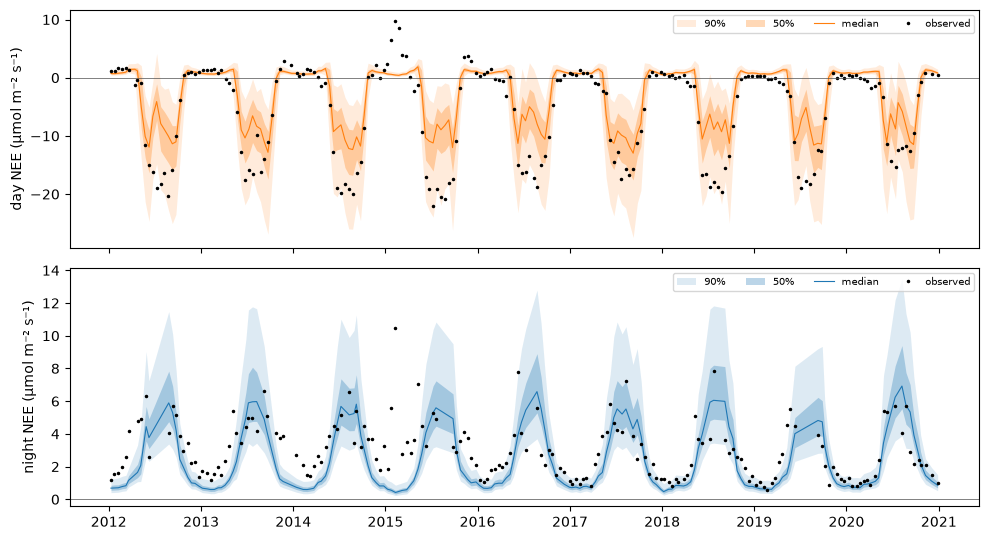

In [4]:
data = load_harvard_forest()
prior_predictions = toy.forward.using(max_evaluations=200)(toy.prior["theta"])
plots.plot_features(data, prior_predictions);

### MCMC

MCMC builds a sequence of parameter values $\theta^{(1)}, \theta^{(2)}, \dots$, a Markov chain,
whose distribution approaches the posterior. Each step proposes a new value and accepts or rejects
it according to the posterior density, which only needs to be known up to a constant. The
*No-U-Turn Sampler* (NUTS) uses the gradient of the log-density to propose distant values that are
still likely to be accepted, which makes it efficient in many dimensions.

The toy problem's forward model can be differentiated, so we can use NUTS. As in the previous
notebook, `condition` returns the posterior, and its `method` says how to compute it. Here we run a
single short chain, which takes about half a minute:

In [5]:
nuts_posterior = toy.condition(
    method="blackjax_nuts",
    method_options={"num_chains": 1, "num_warmup": 100, "num_results": 100},
)
nuts_posterior

EmpiricalDistribution(
    atoms=NumericRecordBatch(
        'theta',
        levels={'chain': 1, 'draw': 100},
        fields=(
            'theta/photosynthetic_capacity',
            'theta/respiration_share',
            'theta/optimum_photosynthesis_temperature',
            'theta/photosynthesis_temperature_range',
            'theta/half_saturation_light',
            'theta/vapor_pressure_deficit_slope',
            'theta/vapor_pressure_deficit_exponent',
            'theta/light_extinction_coefficient',
            'theta/leaf_on_growing_degree_days',
            'theta/leaf_off_day',
            'theta/leaf_on_growth',
            'theta/wood_respiration_rate_at_10c',
            'theta/soil_respiration_flux_at_10c',
            'theta/soil_respiration_q10',
        ),
    ),
    label='posterior',
    fixed=('nee',),
)

The result is a ProbPipe distribution represented by its draws: here 100 of them, too few
for an accurate approximation.

### The reference posterior

An accurate approximation needs much longer chains. The *reference posterior* of the toy problem
was computed by NUTS with 4 chains of 1000 draws each, which takes about 10 minutes, and it is
stored in the repository. We use it throughout this notebook to check the other tools.

In [6]:
reference = load_reference(toy)
reference_posterior = reference.posterior
reference_posterior

EmpiricalDistribution(
    atoms=NumericRecordBatch(
        'record(theta)',
        levels={'chain': 4, 'draw': 1000},
        fields=(
            'theta/photosynthetic_capacity',
            'theta/respiration_share',
            'theta/optimum_photosynthesis_temperature',
            'theta/photosynthesis_temperature_range',
            'theta/half_saturation_light',
            'theta/vapor_pressure_deficit_slope',
            'theta/vapor_pressure_deficit_exponent',
            'theta/light_extinction_coefficient',
            'theta/leaf_on_growing_degree_days',
            'theta/leaf_off_day',
            'theta/leaf_on_growth',
            'theta/wood_respiration_rate_at_10c',
            'theta/soil_respiration_flux_at_10c',
            'theta/soil_respiration_q10',
        ),
    ),
    label='reference',
)

The data inform some parameters much more than others: compare the prior and the
reference posterior marginals.

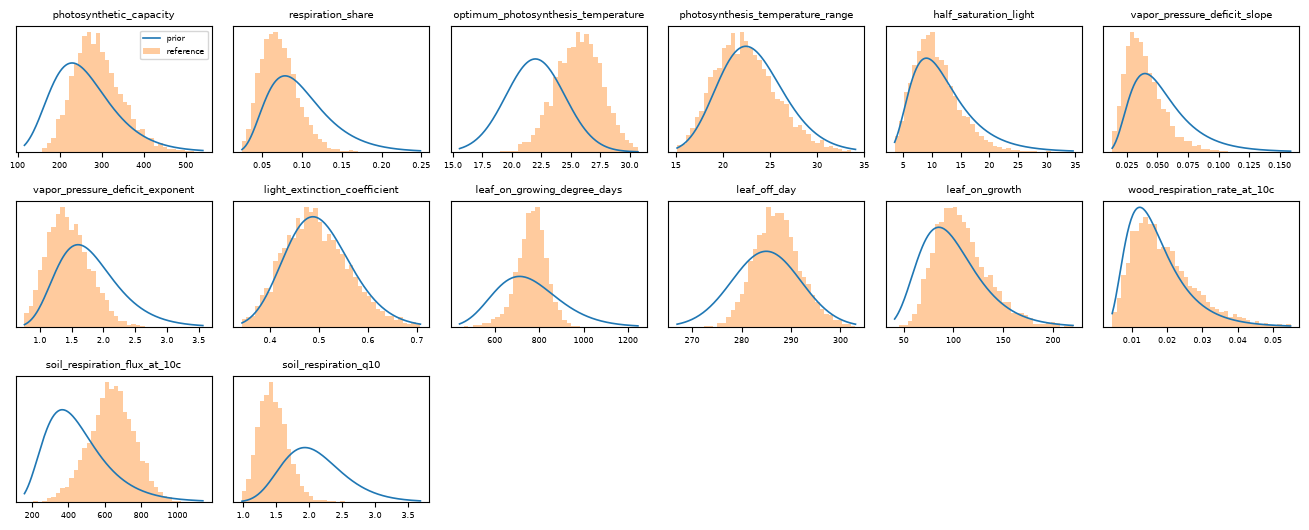

In [7]:
plots.plot_marginals(toy.prior, reference_posterior);

The predictions at 200 draws of the reference posterior are much closer to the data than
those at the prior draws:

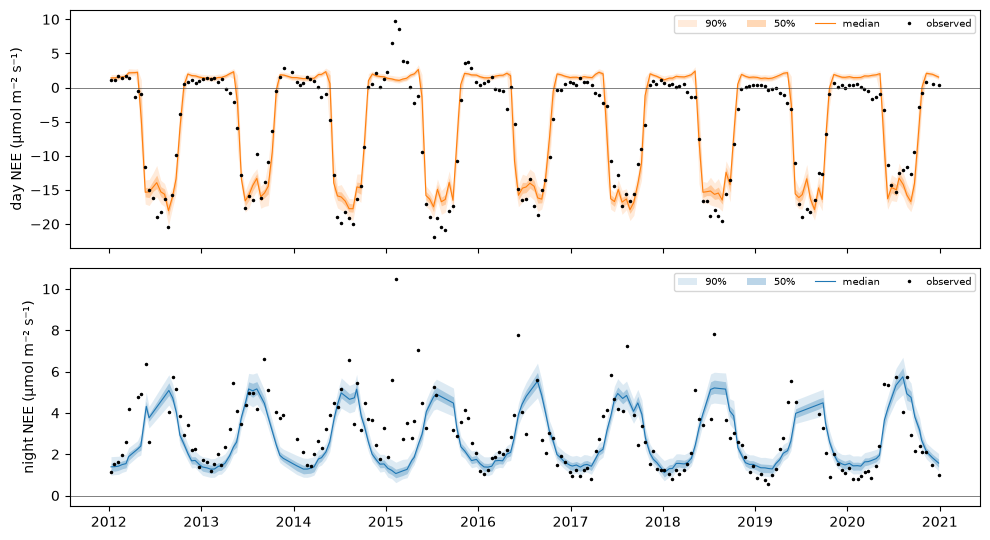

In [8]:
posterior_predictions = toy.forward.using(max_evaluations=200)(reference_posterior["theta"])
plots.plot_features(data, posterior_predictions);

We cannot do the same for SIPNET: it provides no gradients, so NUTS does not apply. MCMC
methods that need no gradients, such as random-walk Metropolis, take far more steps. The reference
posterior of the 10-parameter `harvard_forest_small` problem took about 97,000 SIPNET runs. The
rest of this notebook introduces tools that need far fewer.

## 3. Ensemble Kalman inversion

EKI starts from an *ensemble* of $J$ parameter values, called particles, drawn from the prior. It
works in the unconstrained coordinates $\phi$ from the previous notebook, and it reaches the
posterior through a sequence of *tempered* distributions

$$
\pi_\beta(\phi \mid y) \;\propto\; \pi_0(\phi)\, \mathcal N\!\left(y \mid G(\phi), \Gamma / \beta\right),
\qquad 0 = \beta_0 < \beta_1 < \dots < \beta_T = 1,
$$

where $\Gamma = \operatorname{diag}(\sigma_i^2 / \eta_i)$ is the noise covariance widened by the
learning rate. At $\beta = 0$ this is the prior and at $\beta = 1$ the posterior. Each step runs the
forward model at every particle and moves each particle towards the data with a Kalman update:

$$
\phi_j \;\leftarrow\; \phi_j + C_{\phi G} \left(C_{GG} + \Gamma / \Delta\beta\right)^{-1}
\left(y + \varepsilon_j - G(\phi_j)\right),
\qquad \varepsilon_j \sim \mathcal N(0, \Gamma / \Delta\beta),
$$

where $C_{\phi G}$ and $C_{GG}$ are covariances computed across the ensemble and
$\Delta\beta = \beta_{t+1} - \beta_t$ is chosen adaptively. If the forward model were linear and
the prior Gaussian, the final ensemble would be a sample from the posterior. Otherwise it is an
approximation.

In code, EKI is another `method` of `condition`. `n_particles` sets $J$:

In [9]:
eki_posterior = toy.condition(method="enskit_eki", method_options={"n_particles": 200})
eki_posterior

EmpiricalDistribution(
    atoms=NumericRecordBatch(
        'theta',
        levels={'chain': 1, 'draw': 200},
        fields=(
            'theta/photosynthetic_capacity',
            'theta/respiration_share',
            'theta/optimum_photosynthesis_temperature',
            'theta/photosynthesis_temperature_range',
            'theta/half_saturation_light',
            'theta/vapor_pressure_deficit_slope',
            'theta/vapor_pressure_deficit_exponent',
            'theta/light_extinction_coefficient',
            'theta/leaf_on_growing_degree_days',
            'theta/leaf_off_day',
            'theta/leaf_on_growth',
            'theta/wood_respiration_rate_at_10c',
            'theta/soil_respiration_flux_at_10c',
            'theta/soil_respiration_q10',
        ),
    ),
    label='posterior',
    fixed=('nee',),
)

Here is EKI's approximation against the reference posterior. It finds the region of the
posterior for most parameters, though not its exact shape:

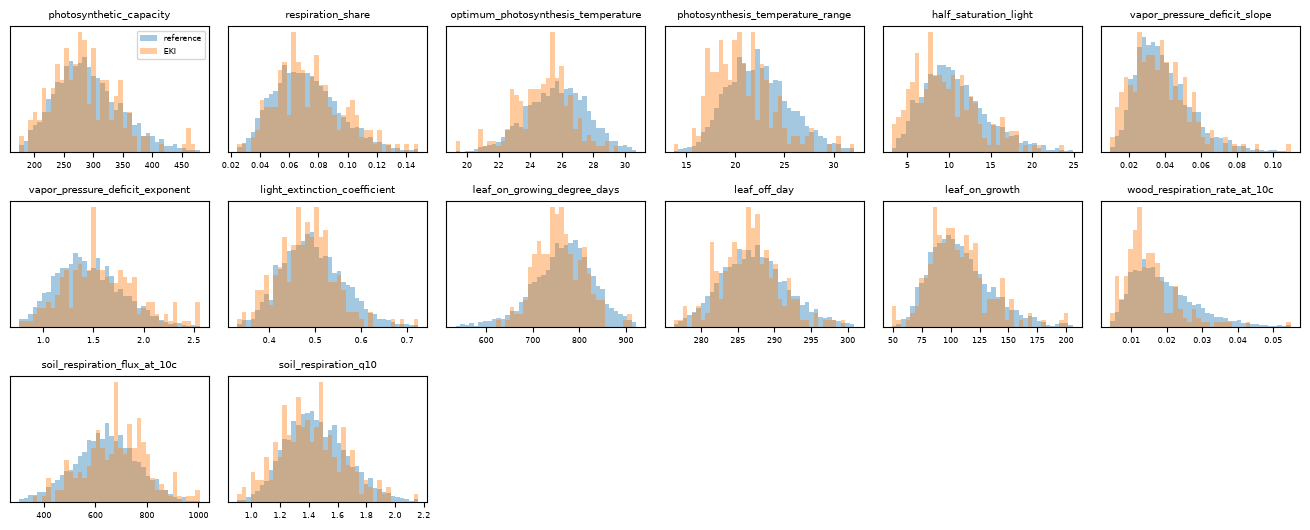

In [10]:
plots.plot_marginals(reference_posterior, eki_posterior, labels=["reference", "EKI"]);

The result also records the run's history. Each row below is one step: the level
$\beta_t$ it started from and the increment $\Delta\beta_t$ it took, the last one reaching
$\beta = 1$. Each step runs the forward model once per particle, so this run cost 200 forward runs
per step:

In [11]:
eki_history = eki_posterior.annotations["arviz/eki_history"]
pd.DataFrame({"beta": eki_history["beta"].values, "increment": eki_history["increment"].values})

,beta,increment
0,0.000000,0.033609
1,0.033609,0.067987
2,0.101595,0.118630
3,0.220225,0.167016
4,0.387242,0.225167
5,0.612409,0.316804
6,0.929212,0.070788


## 4. Active subspaces

### The Jacobian

The active subspace is defined in the whitened coordinates $z$ from the previous notebook, in
which the prior has mean $0$ and covariance $I$, so that every direction is on the same scale.
Write $G(z)$ for the forward model evaluated at the parameters $\theta(z)$. Its *Jacobian* at a
point $z$ is the $n \times d$ matrix of derivatives

$$
DG(z)_{ij} = \frac{\partial G_i}{\partial z_j}(z).
$$

Its column $j$ says how the predictions change as $z_j$ changes. Because the toy model is written
in JAX, `jacobians` computes it exactly. Here at $z = 0$, the centre of the prior:

In [12]:
coordinates = toy.coordinates
centre_jacobian = jacobians(toy, np.zeros(coordinates.dimension))
centre_jacobian.shape

(400, 14)

### The information at a point

The data misfit at $z$ is

$$
\Phi(z) = \tfrac12 \left(y - G(z)\right)^\top \Gamma^{-1} \left(y - G(z)\right).
$$

Replacing $G$ by its linearization at $z$, the curvature of the misfit is the $d \times d$ matrix
$DG(z)^\top \Gamma^{-1} DG(z)$. It is large in the directions in which a small change of $z$ changes
the fit to the data a lot. `toy.noise_variance()` gives the diagonal of $\Gamma$:

In [13]:
gamma = toy.noise_variance()
centre_information = centre_jacobian.T @ (centre_jacobian / gamma[:, None])

In whitened coordinates, the prior's precision is $1$ in every direction. So an
eigenvalue above $1$ means the data inform that direction more than the prior does. At the centre
of the prior, a few directions have very large eigenvalues and the rest much smaller ones:

In [14]:
with np.printoptions(precision=2, suppress=True):
    print(np.linalg.eigvalsh(centre_information)[::-1].clip(min=0))

[47.69 12.22  9.25  2.88  1.08  0.65  0.18  0.1   0.07  0.02  0.01  0.
  0.    0.  ]


### The information matrix

A single point is not representative, so we average over a distribution $\mu$ of points:

$$
H(\mu) = \mathbb E_{z \sim \mu}\!\left[DG(z)^\top \Gamma^{-1} DG(z)\right]
\;\approx\; \frac1N \sum_{m=1}^{N} DG(z_m)^\top \Gamma^{-1} DG(z_m),
\qquad z_m \sim \mu.
$$

To start, $\mu$ is the prior. Here are 500 prior draws in whitened coordinates, their Jacobians,
and the average:

In [15]:
prior_draws = sample(toy.prior, 500)
z_prior = coordinates.whiten(prior_draws["theta"]).to_vector()
prior_jacobians = jacobians(toy, z_prior)
prior_information = np.einsum("mni,n,mnj->ij", prior_jacobians, 1 / gamma, prior_jacobians) / len(
    z_prior
)

### The active subspace

$H$ is symmetric, so it has an eigendecomposition $H = \sum_{i=1}^{d} \lambda_i w_i w_i^\top$, with
$\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d \ge 0$. The leading eigenvectors are the directions
the data inform most. The active subspace of rank $r$ is spanned by the first $r$ of them, the
columns of the $d \times r$ matrix $W = [w_1, \dots, w_r]$.

A `Subspace` holds the eigenvectors and eigenvalues, and the rank:

In [16]:
prior_subspace = Subspace.from_information(
    prior_information, parameter_names=coordinates.names, estimator="exact"
)
prior_subspace

Subspace(estimator='exact', rank=10 of 14, leading eigenvalues [53.6, 20.2, 11.4, 5.13, 3.19, 2.47, 1.7, 1.09, 0.576, 0.382])

`exact_subspace` does the last three steps in one call: Jacobians at the given points,
their average, and the subspace.

In [17]:
prior_subspace = exact_subspace(toy, z_prior)

### Choosing the rank

The rank is chosen from the eigenvalues, the *spectrum* of $H$. By default it is the smallest $r$
whose discarded eigenvalues sum to at most $\varepsilon = 0.5$:
$\sum_{i > r} \lambda_i \le \varepsilon$. The plot shows the spectrum on a log scale, with the
prior's level $\lambda = 1$ dotted.

In [18]:
prior_subspace.rank

10

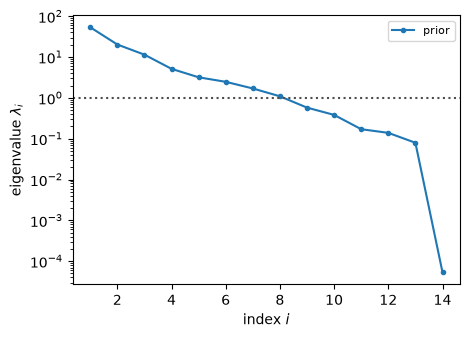

In [19]:
plots.plot_spectra([prior_subspace], labels=["prior"]);

The last eigenvalue is zero. Changing the photosynthetic capacity, the light extinction
coefficient and the leaf-on growth together, in one particular combination, leaves the toy model's
predictions unchanged, so the data cannot inform that direction at all.

`with_rank` gives the same eigenvectors with another rank:

In [20]:
prior_subspace.with_rank(3).basis.shape

(14, 3)

### Loadings

Each direction $w_i$ is a combination of the parameters (in whitened coordinates). Its entries,
the *loadings*, say how much each parameter contributes to it. `loadings()` gives $W$ as a table, and
`plots.plot_loadings` shows one direction:

In [21]:
prior_subspace.loadings().round(2)

,direction_1,direction_2,direction_3,direction_4,direction_5,direction_6,direction_7,direction_8,direction_9,direction_10
parameter,,,,,,,,,,
photosynthetic_capacity,0.71,0.12,0.09,0.03,0.05,0.20,0.09,-0.03,0.04,0.05
respiration_share,-0.10,0.56,0.02,-0.32,-0.25,-0.01,0.46,-0.14,0.49,-0.16
optimum_photosynthesis_temperature,0.05,-0.25,0.03,0.25,-0.07,0.06,-0.40,0.10,0.83,-0.04
photosynthesis_temperature_range,0.05,-0.03,0.01,0.01,0.07,-0.00,-0.04,0.01,0.05,0.01
half_saturation_light,-0.31,0.15,-0.04,-0.30,-0.28,-0.27,-0.46,0.07,-0.04,0.09
vapor_pressure_deficit_slope,-0.19,0.11,-0.03,-0.24,0.25,0.46,-0.13,0.01,0.03,-0.02
vapor_pressure_deficit_exponent,-0.14,0.10,-0.03,-0.26,0.33,0.59,-0.20,0.01,0.01,0.00
light_extinction_coefficient,-0.10,0.05,-0.02,-0.16,-0.11,-0.12,-0.23,0.04,-0.06,-0.02
leaf_on_growing_degree_days,-0.11,-0.05,0.99,-0.04,-0.03,0.03,-0.01,0.01,-0.04,-0.00


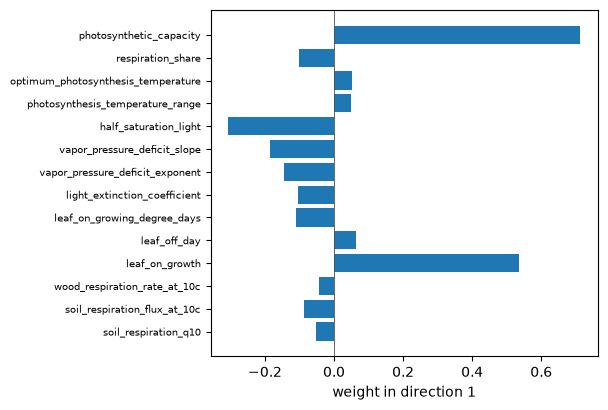

In [22]:
plots.plot_loadings(prior_subspace, 1);

### Activity scores

A parameter's *activity score* summarizes its contribution to the whole active subspace, weighting
each direction by its eigenvalue:

$$
\alpha_j = \sum_{i=1}^{r} \lambda_i W_{ji}^2.
$$

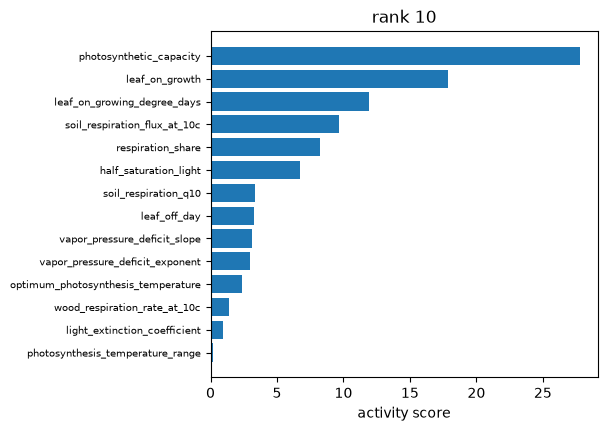

In [23]:
plots.plot_activity_scores(prior_subspace);

### Active and inactive variables

Every point $z$ splits into its coordinates along the active subspace and along its complement, the
*active variables* $a = W^\top z$ and the *inactive variables* $b = W_\perp^\top z$, where the
columns of $W_\perp$ are the remaining eigenvectors. Then $z = W a + W_\perp b$.

In [24]:
active = prior_subspace.active_variables(z_prior)
inactive = prior_subspace.inactive_variables(z_prior)
active.shape, inactive.shape

((500, 10), (500, 4))

If the subspace is a good one, the misfit $\Phi$ changes a lot with the active variables
and hardly at all with the inactive ones. Here is the misfit of each prior draw against its first
active variable and its last inactive one:

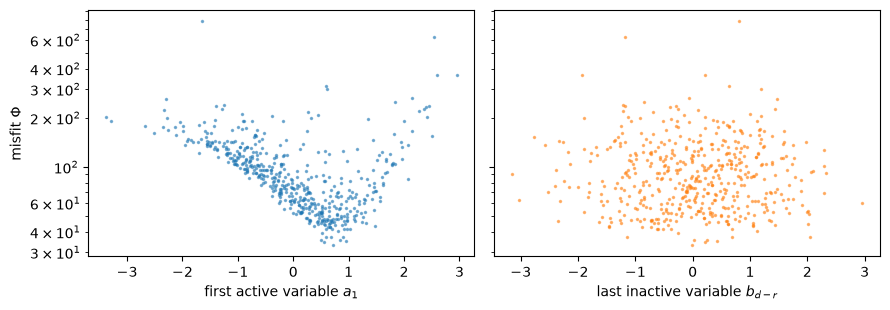

In [25]:
prior_draw_predictions = np.asarray(toy.forward(prior_draws["theta"]))
misfit = 0.5 * np.sum((data.observations - prior_draw_predictions) ** 2 / gamma, axis=1)
plot_misfit_against_variables(misfit, active[:, 0], inactive[:, -1])

### Which distribution to average over

$H(\mu)$ depends on $\mu$. The prior spreads the average over parameter values that fit the data
badly. To sample the posterior, what matters is how the data inform the parameters where the
posterior is, so the natural choice is $\mu = $ the posterior. Here is the subspace averaged over
500 draws of the reference posterior:

In [26]:
posterior_draws = sample(reference_posterior, 500)
z_posterior = coordinates.whiten(posterior_draws["theta"]).to_vector()
posterior_subspace = exact_subspace(toy, z_posterior)
posterior_subspace.rank

10

The two spectra differ:

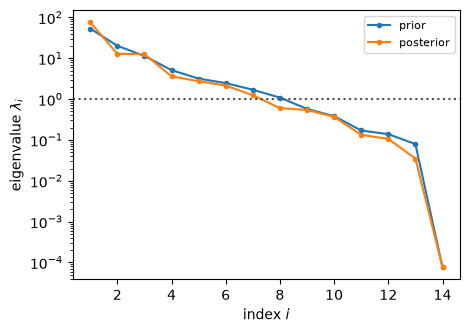

In [27]:
plots.plot_spectra([prior_subspace, posterior_subspace], labels=["prior", "posterior"]);

The *principal angles* between two subspaces measure how far apart they are: $0°$ for a
direction both contain, $90°$ for one that is orthogonal to the other subspace. Here we compare the
four leading directions of each:

In [28]:
posterior_subspace.with_rank(4).principal_angles(prior_subspace.with_rank(4)).round(1)

array([ 0.3,  6.3, 10. , 41. ])

The leading directions nearly agree, but the fourth differs a lot: near the posterior,
the data inform somewhat different combinations of the parameters than across the prior. Keep in
mind that directions whose eigenvalues are close to each other are hard to tell apart, so later
directions differ more even between two good estimates of the same subspace.

But we do not know the posterior: approximating it is the point. The next section
estimates the subspace without gradients, along EKI's path from the prior to the posterior.

## 5. Subspaces without gradients

### Statistical linearization

Given an ensemble of points $z_1, \dots, z_J$ and the predictions $G(z_1), \dots, G(z_J)$, fit the
predictions by least squares with a linear function of $z$, $G(z) \approx c + \widehat{DG}\, z$. Its
slope is

$$
\widehat{DG} = C_{Gz}\, C_{zz}^{-1},
$$

with $C_{Gz}$ and $C_{zz}$ the covariances across the ensemble. This is the *statistical
linearization* of $G$ over the ensemble. If $G$ is linear, $\widehat{DG}$ is its Jacobian; for an
ensemble drawn from a Gaussian, it estimates the average Jacobian $\mathbb E[DG(z)]$. It needs only
the forward runs at the ensemble, and no gradients.

Here is the statistical linearization over the prior draws, from their predictions computed
above:

In [29]:
slope = statistical_linearization(z_prior, prior_draw_predictions)
slope.shape

(400, 14)

It is close to the average of the exact Jacobians at the same points:

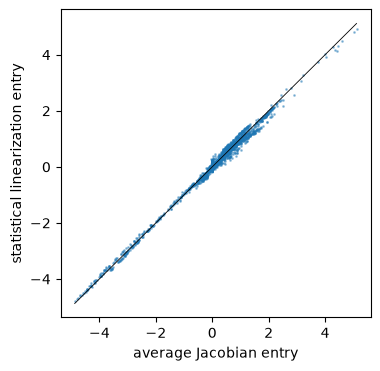

In [30]:
plot_slope_against_jacobian(prior_jacobians.mean(axis=0), slope)

### The information from a linearization

Replacing the Jacobians by the slope gives an estimate of the information matrix,

$$
\hat H = \widehat{DG}^\top \Gamma^{-1} \widehat{DG}.
$$

It averages the Jacobian before squaring it, so its eigenvalues are smaller than those of $H(\mu)$,
but its leading directions are usually close.

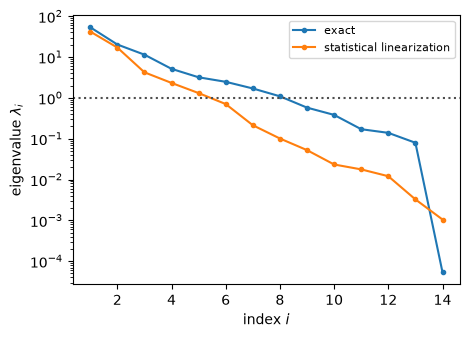

In [31]:
slope_information = slope.T @ (slope / gamma[:, None])
slope_subspace = Subspace.from_information(
    slope_information, parameter_names=coordinates.names, estimator="statistical_linearization"
)
plots.plot_spectra([prior_subspace, slope_subspace], labels=["exact", "statistical linearization"]);

Its three leading directions are within a few degrees of those of the exact subspace;
the fourth is not:

In [32]:
slope_subspace.with_rank(4).principal_angles(prior_subspace.with_rank(4)).round(1)

array([ 2.7,  3.9,  4.2, 53.1])

### Linearizing along EKI

EKI's ensembles move from the prior, at $\beta = 0$, to the approximate posterior, at $\beta = 1$.
Linearizing the ensemble at each step $t$ and weighting each step by its increment gives an
estimate of the information averaged along that path:

$$
\hat H = \sum_{t} \Delta\beta_t\, \widehat{DG}_t^\top \Gamma^{-1} \widehat{DG}_t.
$$

It costs no forward runs beyond EKI's own.

EKI accepts *callbacks*: functions it calls after each step with a record of that step's particles
and predictions. `LadderLinearization` is such a callback; it computes and accumulates the
linearizations:

In [33]:
ladder = LadderLinearization(coordinates)
eki_posterior = toy.condition(
    method="enskit_eki", method_options={"n_particles": 200, "callbacks": [ladder]}
)
len(ladder.steps)

6

Its `subspace` method gives the subspace of $\hat H$:

In [34]:
ladder_subspace = ladder.subspace()
ladder_subspace.rank

7

Its spectrum is lower than the exact ones, as expected:

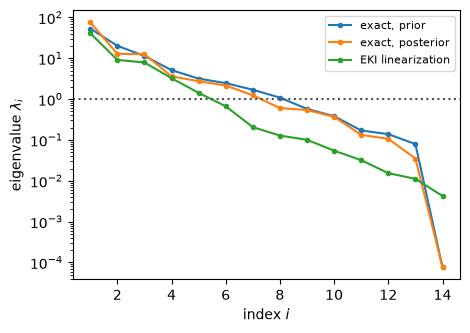

In [35]:
plots.plot_spectra(
    [prior_subspace, posterior_subspace, ladder_subspace],
    labels=["exact, prior", "exact, posterior", "EKI linearization"],
);

and its three leading directions are within a few degrees of those of the posterior
subspace, which it estimates without gradients and without knowing the posterior:

In [36]:
ladder_subspace.with_rank(4).principal_angles(posterior_subspace.with_rank(4)).round(1)

array([ 0.9,  4.2,  7.5, 34.8])

`plots.plot_sufficient_summary` shows the misfit of every EKI particle, from every step,
against its active variables. The misfit falls as the particles move towards the posterior, and it
changes mostly along the first active variable:

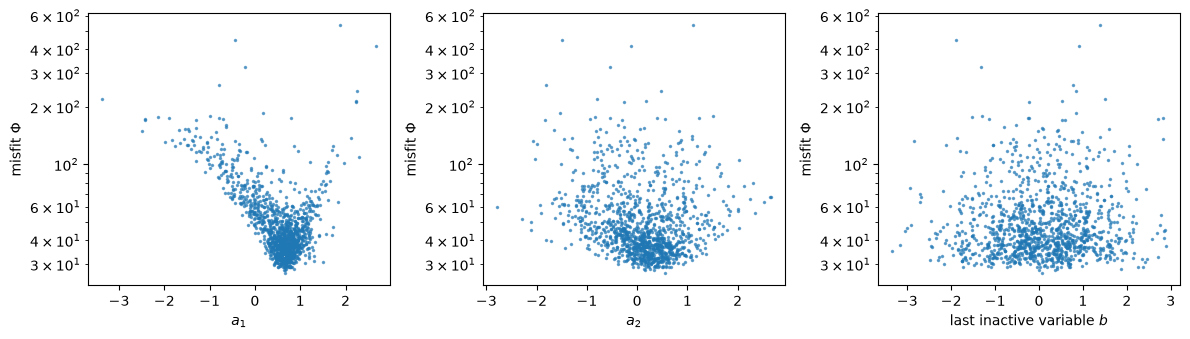

In [37]:
plots.plot_sufficient_summary(toy, eki_posterior.annotations["arviz/eki_history"], ladder_subspace);

### Additional details: a subspace from posterior draws

Another estimate needs only draws of the posterior. For a linear forward model and a Gaussian
prior, the posterior covariance in whitened coordinates is $\Sigma = (I + H)^{-1}$, so
$H = \Sigma^{-1} - I$. `covariance_subspace` takes posterior draws of the parameters and uses this
formula; here with the reference draws:

In [38]:
covariance_estimate = covariance_subspace(toy, posterior_draws["theta"].to_vector())
covariance_estimate.with_rank(4).principal_angles(posterior_subspace.with_rank(4)).round(1)

array([ 1.3,  5.4,  9.2, 24. ])

## 6. Reduced problems

### The reduced posterior

Writing $z = W a + W_\perp b$, the *reduced problem* keeps the active variables $a$ and fixes the
inactive ones at their prior mean $b = 0$ in the likelihood:

$$
\pi_r(a \mid y) \;\propto\; \mathcal N(a \mid 0, I) \prod_{i=1}^{n} p\!\left(y_i \mid \theta(W a)\right)^{\eta_i}.
$$

This makes two approximations: the fit to the data ignores $b$, and the prior of $a$ is taken to be
standard normal, which is exact only if the prior is Gaussian in the unconstrained coordinates. Both
are good when the data barely inform $b$.

`reduced_problem` builds it from a problem and a subspace. It is an inverse problem like any other,
whose parameters are the $r$ active variables:

In [39]:
reduced = reduced_problem(toy, ladder_subspace)
print(reduced.describe())

toy_reduced: toy reduced to 7 active variables, the inactive ones at their prior mean in the likelihood.
Calibration parameters (7): active_1, active_2, active_3, active_4, active_5, active_6, active_7
Observations: nee (400 values)


### Sampling the reduced posterior

The reduced problem has only a few parameters, so MCMC without gradients is affordable.
*Random-walk Metropolis* proposes a random step from the current value and accepts it with
probability $\min\left(1, \pi_r(a' \mid y) / \pi_r(a \mid y)\right)$. It needs only the density,
which is why it also works for SIPNET. Here 4 chains of 1000 draws, after 500 steps of warmup:

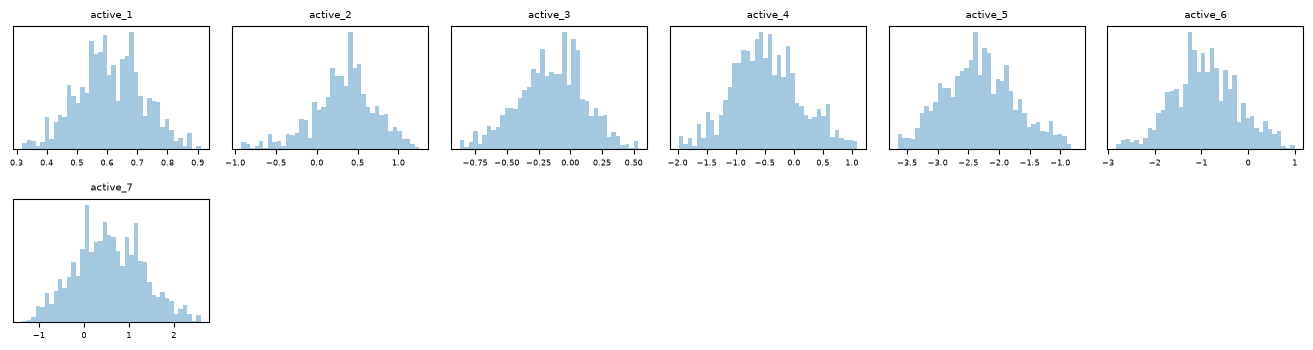

In [40]:
reduced_posterior = reduced.condition(
    method="blackjax_rwmh",
    method_options={"num_chains": 4, "num_warmup": 500, "num_results": 1000},
)
plots.plot_marginals(reduced_posterior);

### Lifting back to all parameters

A draw of $a$ determines only the active part of $z$. *Lifting* completes it with an independent
draw of the inactive variables from their prior, $b \sim \mathcal N(0, I)$, and maps the result to
the parameters, $\theta(W a + W_\perp b)$. The lifted draws approximate the full posterior. `lift`
takes the reduced posterior and a random key:

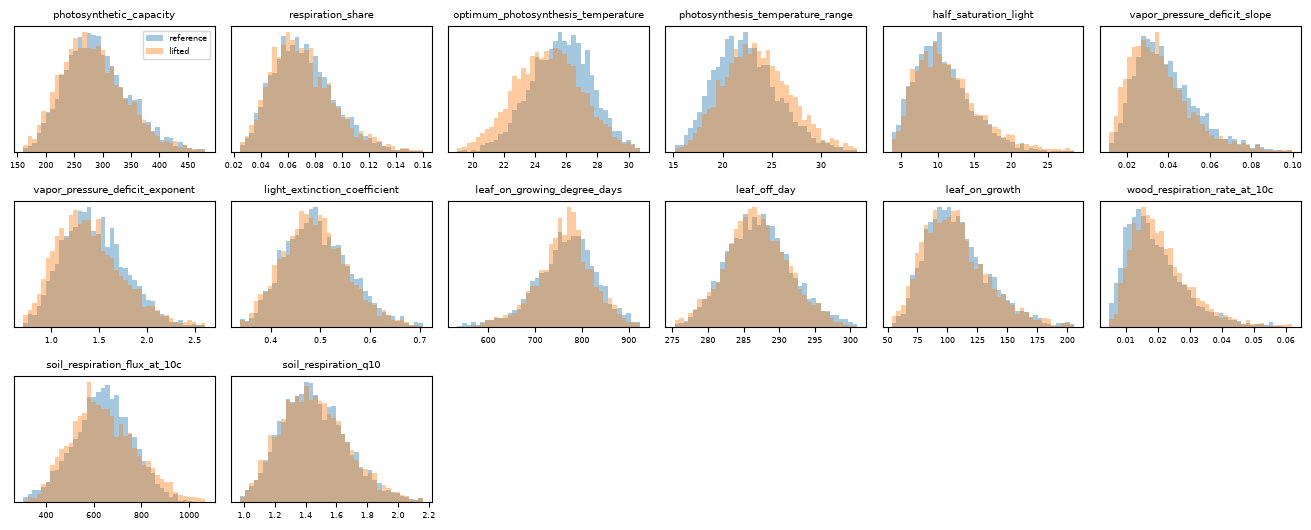

In [41]:
lifted = reduced.lift(reduced_posterior, key=jax.random.key(0))
plots.plot_marginals(reference_posterior, lifted, labels=["reference", "lifted"]);

## 7. Putting it together

`active_subspace_mcmc` runs the steps of sections 3 to 6 in one call:

1. EKI with `LadderLinearization` as a callback (sections 3 and 5);
2. the subspace of the ladder's estimate, with the rank chosen from its spectrum (section 4);
3. random-walk Metropolis on the reduced problem, started at the EKI ensemble's mean (section 6);
4. the lift of its draws (section 6).

In [42]:
result = active_subspace_mcmc(toy, seed=1)

The result holds the approximate posterior, the subspace, and the forward runs of each
stage:

In [43]:
result.subspace.rank, result.forward_runs

(7, {'exploration': 600, 'sampling': 6004})

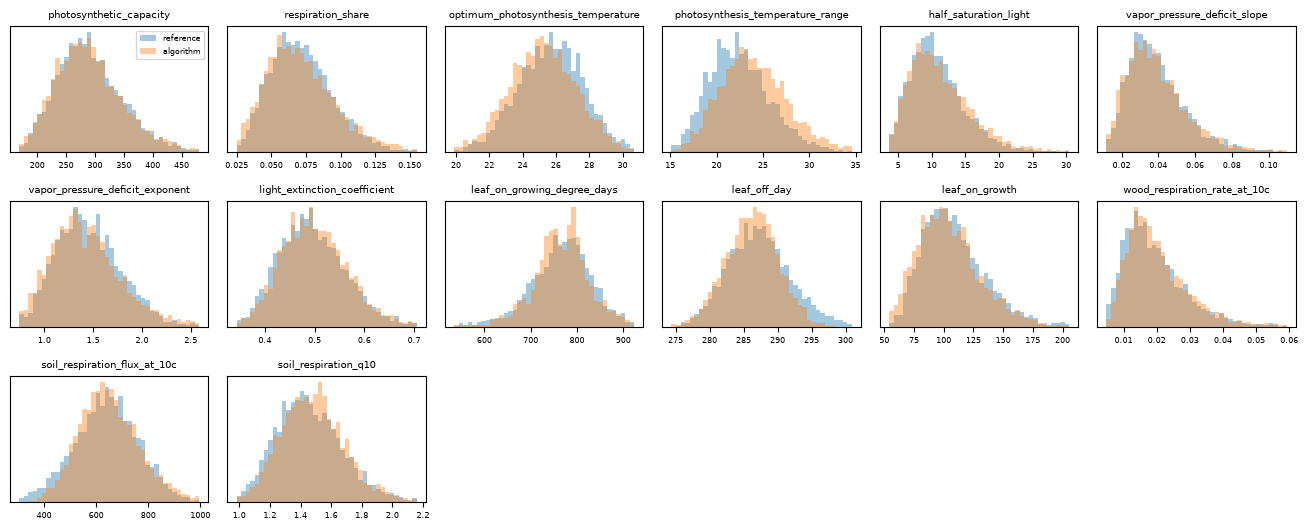

In [44]:
plots.plot_marginals(reference_posterior, result.posterior, labels=["reference", "algorithm"]);

The next notebook compares algorithms and their settings against the reference
posterior over many runs.

## 8. Additional details: learning noise scales

So far the noise scales have been fixed. With `scales="inferred"`, the noise scales $s^2_k$ of the
previous notebook are parameters too. EKI handles them with an extra step: after each move, it
draws each particle's scales from their conditional distribution given the particle, which is
inverse-gamma.

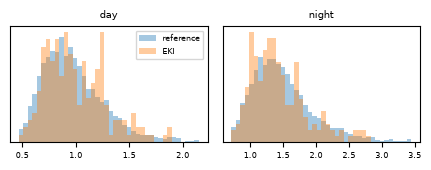

In [45]:
toy_with_scales = load_inverse_problem("toy", scales="inferred")
eki_with_scales = toy_with_scales.condition(
    method="enskit_eki", method_options={"n_particles": 200}
)
reference_with_scales = load_reference(toy_with_scales).posterior
plots.plot_marginals(
    reference_with_scales["s2"], eki_with_scales["s2"], labels=["reference", "EKI"], columns=2
);

The information matrix depends on the scales through $\Gamma$, so the estimators take
values for them, such as `exact_subspace(problem, z, noise_scales={"day": ..., "night": ...})`.
In `active_subspace_mcmc`, the ladder estimate uses the noise covariance at EKI's current scales at
each step, and the reduced problem keeps the scales as parameters, so random-walk Metropolis samples
them along with the active variables.

## 9. Mathematical details

### The information matrix

For a law $\mu$ of whitened coordinates,
$H(\mu) = \mathbb E_\mu\!\left[DG(z)^\top \Gamma^{-1} DG(z)\right]$, with
$\Gamma = \operatorname{diag}(s^2_{k(i)} \sigma^2_i / \eta_i)$. If $G(z) = G_0 + A z$ is linear,
the prior in whitened coordinates is $\mathcal N(0, I)$ and the scales are fixed, the posterior is
Gaussian with precision $I + A^\top \Gamma^{-1} A = I + H$. So $\lambda_i > 1$ marks a direction
the data inform more than the prior does, and the posterior variance along $w_i$ is
$1 / (1 + \lambda_i)$.

### Statistical linearization

For an ensemble $z_1, \dots, z_J$ with mean $\bar z$ and predictions with mean $\bar G$,

$$
C_{zz} = \frac{1}{J - 1} \sum_j (z_j - \bar z)(z_j - \bar z)^\top, \qquad
C_{Gz} = \frac{1}{J - 1} \sum_j \left(G(z_j) - \bar G\right)(z_j - \bar z)^\top, \qquad
\widehat{DG} = C_{Gz}\, C_{zz}^{-1}.
$$

If the ensemble is drawn from $\mathcal N(m, C)$, Stein's lemma gives
$\operatorname{Cov}(G(z), z) = \mathbb E[DG(z)]\, C$, so $\widehat{DG}$ estimates
$\mathbb E[DG(z)]$. Then $\widehat{DG}^\top \Gamma^{-1} \widehat{DG}$ estimates
$\mathbb E[DG]^\top \Gamma^{-1} \mathbb E[DG]$, which is smaller than $H(\mu)$ by
$\mathbb E\!\left[(DG - \mathbb E DG)^\top \Gamma^{-1} (DG - \mathbb E DG)\right]$. When the ensemble
has no more particles than parameters, the slope is fitted on the span of the particles.

### EKI

EKI targets the tempered posteriors
$\pi_\beta(\phi \mid y) \propto \pi_0(\phi)\, \mathcal N(y \mid G(\phi), \Gamma / \beta)$ in
unconstrained coordinates. At each step it chooses the largest increment $\Delta\beta_t$ for which
the importance weights $\exp(-\Delta\beta_t\, \Phi(\phi_j))$ from $\beta_t$ to
$\beta_t + \Delta\beta_t$ keep an effective sample size of at least half the ensemble, then moves
every particle by the Kalman update of section 3, with perturbed observations. With inferred noise
scales it then draws each particle's scales from their inverse-gamma conditional at the new level.
`lsmas.inference.EnsKitEKI` documents the details.

### The ladder estimate

`LadderLinearization` accumulates $\hat H = \sum_t w_t\, \widehat{DG}_t^\top \Gamma_t^{-1}
\widehat{DG}_t$ over the steps $t$ of an ensemble run, with $w_t = \Delta\beta_t$ by default (a
Riemann sum over the tempering levels), $w_t = 1/T$ with `weighting="uniform"`, or only the last
step with `weighting="last"`.

### The rank

By default the rank is the smallest $r$ with $\sum_{i > r} \lambda_i \le \varepsilon$, with
$\varepsilon = 0.5$ (`discarded_information`).

### The reduced problem and the lift

The reduced posterior is
$\pi_r(a \mid y) \propto \mathcal N(a \mid 0, I) \prod_i p(y_i \mid \theta(W a))^{\eta_i}$, with
any inferred noise scales kept as parameters. The lift maps a draw $a$ to $\theta(W a + W_\perp b)$
with $b \sim \mathcal N(0, I)$ independent of $a$, which is the posterior when the likelihood does
not depend on $b$ and the prior is $\mathcal N(0, I)$ in whitened coordinates.

### Symbols and code

| Symbol | Meaning | In code |
|---|---|---|
| $z$ | whitened coordinates | `problem.coordinates.whiten` |
| $DG(z)$ | the Jacobian of the forward model in $z$ | `jacobians(problem, z)` |
| $\Gamma$ | the noise covariance widened by the learning rate | `problem.noise_variance()` |
| $H(\mu)$ | the information matrix averaged over $\mu$ | `exact_subspace(problem, z).information` |
| $\lambda_i$, $w_i$ | its eigenvalues and eigenvectors | `subspace.eigenvalues`, `subspace.eigenvectors` |
| $r$, $W$, $W_\perp$ | the rank and the bases of the subspace and its complement | `subspace.rank`, `subspace.basis`, `subspace.complement` |
| $a$, $b$ | the active and inactive variables | `subspace.active_variables(z)`, `subspace.inactive_variables(z)` |
| $\alpha_j$ | the activity scores | `subspace.activity_scores()` |
| $\widehat{DG}$ | a statistical linearization | `statistical_linearization(z, predictions)` |
| $\hat H$ | the ladder estimate along EKI | `LadderLinearization(problem.coordinates)` |
| $\pi_r(a \mid y)$ | the reduced posterior | `reduced_problem(problem, subspace)` |